# 01 · Imágenes, color y filtros

Una imagen es una matriz de números. Antes de las redes, la visión se hacía con operaciones fijas:
convoluciones (suavizado, bordes), espacios de color e histogramas de textura. Siguen siendo útiles
como baseline y explican qué aprende la primera capa de una CNN. Usaremos una «mazorca» sintética:
una elipse verde-amarilla con manchas café.

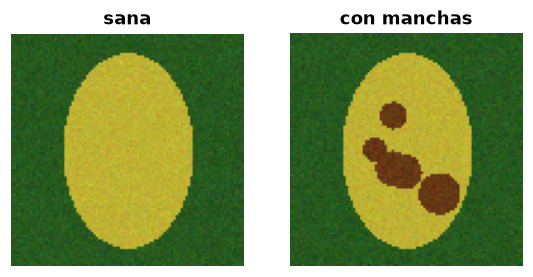

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from common import set_seed, setup_style

setup_style()
rng = set_seed(42)
from applied_cv.image import (
    color_histogram,
    conv2d,
    local_binary_pattern,
    rgb_to_gray,
    rgb_to_hsv,
    sobel,
)


def pod(n_spots, size=96):
    yy, xx = np.mgrid[0:size, 0:size] / size
    img = np.full((size, size, 3), [0.15, 0.35, 0.12])  # follaje
    body = ((xx - 0.5) / 0.28) ** 2 + ((yy - 0.5) / 0.42) ** 2 < 1
    img[body] = [0.75, 0.70, 0.20]  # mazorca amarillo-verdosa
    for _ in range(n_spots):
        cy, cx, r = rng.uniform(0.25, 0.75), rng.uniform(0.35, 0.65), rng.uniform(0.04, 0.09)
        img[body & (((xx - cx) ** 2 + (yy - cy) ** 2) < r**2)] = [0.40, 0.22, 0.08]  # café
    return (img + rng.normal(0, 0.03, img.shape)).clip(0, 1)


healthy, sick = pod(0), pod(5)
fig, ax = plt.subplots(1, 2, figsize=(6, 3))
for a, im, t in zip(ax, (healthy, sick), ("sana", "con manchas"), strict=True):
    a.imshow(im)
    a.set_title(t)
    a.axis("off")

## 1. Convolución: suavizado y bordes

`conv2d` desliza un núcleo y suma productos. Un núcleo de promedios suaviza; los de Sobel responden
a cambios bruscos de intensidad (bordes).

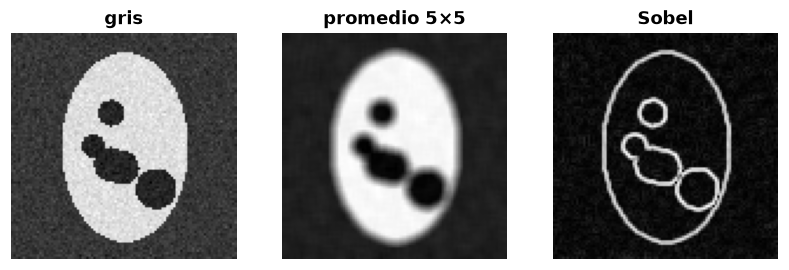

In [2]:
gray = rgb_to_gray(sick)
blur = conv2d(gray, np.full((5, 5), 1 / 25))
edges = sobel(gray)
fig, ax = plt.subplots(1, 3, figsize=(9, 3))
for a, im, t in zip(ax, (gray, blur, edges), ("gris", "promedio 5×5", "Sobel"), strict=True):
    a.imshow(im, cmap="gray")
    a.set_title(t)
    a.axis("off")

## 2. Color: RGB frente a HSV

En RGB, «café» y «amarillo oscuro» se mezclan con la iluminación. El **tono** (H) de HSV separa el
color de la luz: las manchas forman un pico propio en el histograma de H.

distancia L1 entre histogramas HSV: sana-sana 0.068  sana-manchas 0.356


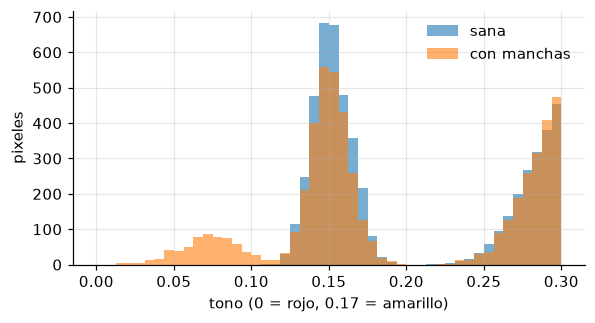

In [3]:
hsv_h, hsv_s = rgb_to_hsv(healthy), rgb_to_hsv(sick)
fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(hsv_h[..., 0].ravel(), bins=48, range=(0, 0.3), alpha=0.6, label="sana")
ax.hist(hsv_s[..., 0].ravel(), bins=48, range=(0, 0.3), alpha=0.6, label="con manchas")
ax.set(xlabel="tono (0 = rojo, 0.17 = amarillo)", ylabel="pixeles")
ax.legend()
diff = np.abs(color_histogram(healthy) - color_histogram(sick)).sum()
other = pod(0)  # otra mazorca sana: cuánto difieren dos imágenes de la misma clase
same = np.abs(color_histogram(healthy) - color_histogram(other)).sum()
print(f"distancia L1 entre histogramas HSV: sana-sana {same:.3f}  sana-manchas {diff:.3f}")

## 3. Textura: LBP

El patrón binario local compara cada pixel con sus 8 vecinos sobre un círculo y arma un código de
8 bits. No depende del brillo global, solo de quién es mayor que quién. Con ruido de sensor aparecen
casi todos los códigos en cualquier imagen: lo informativo son sus **proporciones**.

In [4]:
codes = {
    name: local_binary_pattern(np.round(rgb_to_gray(im) * 255))
    for name, im in (("sana", healthy), ("otra sana", other), ("con manchas", sick))
}
hists = {name: np.bincount(c.ravel(), minlength=256) / c.size for name, c in codes.items()}
for name, p in hists.items():
    print(f"{name:12s} códigos distintos: {np.count_nonzero(p):3d}")
d_same = np.abs(hists["sana"] - hists["otra sana"]).sum()
d_diff = np.abs(hists["sana"] - hists["con manchas"]).sum()
print(f"distancia L1 entre histogramas LBP: sana-sana {d_same:.3f}  sana-manchas {d_diff:.3f}")

sana         códigos distintos: 253
otra sana    códigos distintos: 253
con manchas  códigos distintos: 254
distancia L1 entre histogramas LBP: sana-sana 0.138  sana-manchas 0.155


**Lectura.** Las dos comparaciones importan: un rasgo sirve si separa clases **más** de lo
que varía dentro de una clase. Aquí el color separa con claridad y el LBP apenas, porque las manchas
sintéticas son planas y el ruido domina la micro-textura; en mazorcas reales la esporulación (m3) sí
tiene textura propia. El baseline «color + textura» del proyecto usa exactamente estos
rasgos con una regresión logística: si una CNN no lo supera, no está viendo más que «manchas café».